In [2]:
import pandas as pd
import numpy as np
import re
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances
from sklearn.preprocessing import normalize
from sentence_transformers import SentenceTransformer

In [4]:
raw_txns = [
    "AMAZON MUMBAI IN", "UPI-CRED GIFTCARD",

    "AMAZON INDIA CYBS SI MUMBAI IN",
    "UPI-CRED", "SWIGGY GURGAON IN", "UPI-SWIGGY",
    "AMAZON PAY INDIA PVT L WWW.AMAZON.IN IND", "PRINCIPAL CREDIT ADJ",
    "AMAZON GURGAON IN", "AMAZON PRIME4R2LM9185 AMAMZN.CO.UK/PM...",
    "UPI-Swiggy Limited", "UPI-Apple Services",
    "Amazon Prime Membership amzn.com/prme WA", "CREDIT BALANCE REFUND CLOSED CARD-0813",
    "Swiggy Food Bangalore KA", "AMAZON MUMBAI MAH",
    "Swiggy Limited Bangalore IN",
    "GOOGLE VNG SINGAPORE g.co/helppay#CA", "AMAZON IN BILL PAYMENT MUMBAI IND",
    "ANNUAL FEE CREDIT ADJUSTMENT", "WWW AMAZON IN GURGAON IND", "AMAZON MUMBAI IND",
    "Swiggy Limited Bengaluru IN", "MARUTI INSURANCE NATIKOLKATTA IND",
    "AMAZON PRIME MEMBERSHI TOKYO JPN", "UPI-Amazon India",
    "Airindia South West Dein",
    "AMAZON WALLET LOAD MUMBAI IN", "AMAZON GIFT CARD MUMBAI IND",
    "AGGREGATOR EMI - OFFUS CREDIT", "Amazon Seller Services PrKARNATAKA IN",
    "AMAZON SELLER SERVICES MUMBAI IND", "Amazon.ca Prime Member amazon.ca/priBC",
    "AMZN UTILITIES MUMBAI IND", "MARUTI INSURANCE SBI GEMUMBAI IND",
    "SWIGGY LIMITED Bengaluru IN", "PayUSwiggy Limited Bangalore KAR",
    "AMAZON PAY INDIA PRIVA Bangalore IND", "UPI-ARCHANA MARUTI HIVAR",
    "AMAZON MKTPLNS2P80ZI3 Amzn.com/billWA", "SWIGGY IN BANGALORE IN",
    "UPI-APPLE SHOPPING MALL AC", "INTEREST CREDIT ADJ", "CRED MUMBAI IN",
    "UPI-Swiggy Diners", "CRED TELECOM MUMBAI IND", "APPLE INDIA PVT LTD PUNE IN",
    "SWIGGY BANGALORE IND", "AMZAvis Rent a Car pay.amazon.coNJ",
    "WWW SWIGGY COM GURGAON IN",
    "PTMSWIGGY IN BANGALORE KAR", "MARUTI INSURANCE ROYAL CHENNAI IND",
    "Cred Mumbai IN", "UPI-CREDPAYSWIGGY1", "SWIGGY GURGOAN hrIN",
    "LINKEDIN Singapore SG", "APPLE PLANET CARE BENGALURU IND",
    "AIRINDIABSP IN NEW DELHI IND", "PYUSwiggy Food Bangalore IND",
    "WWW SWIGGY IN BANGALORE IND",
    "AMAZON GIFT CARD MUMBAI IN", "Amazon web services aws.amazon.coWA",
    "SWIGGY DINEOUT BENGALURU IN", "CashfreeSWIGGY LIMITE Bengaluru KAR",
    "APPLE SHOPPING MALL MADURAI IND", "M-AMAZON SELLER SERVIC, P:01,000071790259",
    "Amazon Pay India Priva Bangalore Ind", "AIRINDIAWINR BARODA IN",
    "Amazon Prime2G3CT9W00 Amzn.com/bill WA", "MARUTI INSURANCE ROYA CHENNAI TAM",
    "INDAIR IA LTD (INR WWW.AIRINDIA.IN)", "AMAZON WEB SERVICES MUMBAI IN",
    "SWIGGY BENGALURU IN", "GOOGLE ADS4949671103 Singapore SGP",
    "Amazon Prime7J93E9SX3 Amzn.com/billWA", "Amazon.ae Dubai AE",
    "AIR INDIA LTD BARODA GUJ", "GOOGLE ADS4949671103 Singapore SGP",
    "Amazon Prime7J93E9SX3 Amzn.com/billWA", "Amazon.ae Dubai AE",
    "AIR INDIA LTD BARODA GUJ", "CRED GURGAON IND", "AMAZON RECHARGES MUMBAI IND",
    "SWIGGY FOOD BANGALORE KA", "Add_TajHotel_AirIndia_rev", "AMAZON MUMBAI IND",
    "CRED UTILITIES MUMBAI MHIN", "CREDIT CARD PAYMENT URSE",
    "CRED TELECOM BANGALORE IND", "CRED FASTAG MUMBAI IND",
    "AMAZON MARKETING SERVICES MUMBAI IN", "GENSPARK.AI SINGAPORE SG",
    "AMAZONIA CAFE BKC MUMBAI", "POS AMAZONIA RESTAURANT MUMBAI",
    "UPI-AMAZONIA CAFE", "AMAZONIA HOSPITALITY PVT LTD MUMBAI",
    "WWW AMAZONIA CAFE INDIA"
]

df = pd.DataFrame(raw_txns, columns=['txn_desc'])
print(f"Total Transactions Description: {len(df)}")

Total Transactions Description: 97


In [5]:
df.head()

,txn_desc
0,AMAZON MUMBAI IN
1,UPI-CRED GIFTCARD
2,AMAZON INDIA CYBS SI MUMBAI IN
3,UPI-CRED
4,SWIGGY GURGAON IN


In [6]:
# CELL 3: SAFE STRUCTURAL NORMALIZATION

import re

def safe_preprocess_text(text):
    text = text.lower()
    text = re.sub(r'(https?://|www\.)[^\s]+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\b\d{5,}\b', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_txn'] = df['txn_desc'].apply(safe_preprocess_text)
print("Cell 3 Updated: Pure Structural Normalization Active (0% Manual Lists).")

Cell 3 Updated: Pure Structural Normalization Active (0% Manual Lists).


In [7]:
df.head()

,txn_desc,clean_txn
0,AMAZON MUMBAI IN,amazon mumbai in
1,UPI-CRED GIFTCARD,upi cred giftcard
2,AMAZON INDIA CYBS SI MUMBAI IN,amazon india cybs si mumbai in
3,UPI-CRED,upi cred
4,SWIGGY GURGAON IN,swiggy gurgaon in


In [8]:
# CELL 3.5: PURE STATISTICAL COMPOUND TOKEN SPLITTER (0% Manual Rules)

import re
from collections import Counter

def dynamic_split_compounds(df, text_col='clean_txn'):
    """
    Splits compound tokens (e.g. 'payuswiggy' -> 'payu swiggy', 'airindiabsp' -> 'airindia bsp')
    purely using sub-string frequency statistics across the corpus.
    """
    def split_numbers(text):
        text = re.sub(r'([a-z]{3,})(\d+)', r'\1 \2', text)
        return re.sub(r'(\d+)([a-z]{3,})', r'\1 \2', text)

    df[text_col] = df[text_col].apply(split_numbers)

    all_tokens = " ".join(df[text_col]).split()
    token_counts = Counter(all_tokens)

    corpus_roots = sorted(
        [token for token, count in token_counts.items() if len(token) >= 4 and count >= 2],
        key=len,
        reverse=True
    )

    def split_embedded_roots(text):
        tokens = text.split()
        new_tokens = []
        for t in tokens:
            split_applied = False
            if len(t) > 7:
                for root in corpus_roots:
                    if root in t and t != root:
                        idx = t.find(root)
                        if idx > 0:
                            prefix = t[:idx]
                            suffix = t[idx:]
                            new_tokens.extend([prefix, suffix])
                            split_applied = True
                            break
            if not split_applied:
                new_tokens.append(t)
        return " ".join(new_tokens)

    df[text_col] = df[text_col].apply(split_embedded_roots)
    return df

df = dynamic_split_compounds(df, text_col='clean_txn')
print(" Cell 3.5 Complete: 100% Unsupervised Compound Token Splitter Ready.")

 Cell 3.5 Complete: 100% Unsupervised Compound Token Splitter Ready.


In [9]:
df.head()

,txn_desc,clean_txn
0,AMAZON MUMBAI IN,amazon mumbai in
1,UPI-CRED GIFTCARD,upi cred gift card
2,AMAZON INDIA CYBS SI MUMBAI IN,amazon india cybs si mumbai in
3,UPI-CRED,upi cred
4,SWIGGY GURGAON IN,swiggy gurgaon in


In [10]:
# CELL 4: LOWER LAYER (Parameter-Aware Feature Space)

import numpy as np
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_distances
from sentence_transformers import SentenceTransformer

if 'sbert_model' not in globals():
    print("⏳ Initializing SentenceTransformer model ('all-MiniLM-L6-v2')...")
    sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

def lower_layer_extract_features(df, text_col='clean_txn', noise_mask=set()):
    """
    Constructs hybrid feature space (80% Char N-Grams + 20% SBERT).
    Suppresses tokens present in `noise_mask` back-propagated from Cell 6.
    """
    def mask_tokens(text):
        tokens = [w for w in text.split() if w not in noise_mask and len(w) > 1]
        return " ".join(tokens) if tokens else text

    df['masked_txn'] = df[text_col].apply(mask_tokens)

    char_vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5))
    X_char = char_vectorizer.fit_transform(df['masked_txn'])
    X_char_norm = normalize(X_char, norm='l2', axis=1)

    X_sbert = sbert_model.encode(df['masked_txn'].tolist(), show_progress_bar=False, convert_to_numpy=True)
    X_sbert_norm = normalize(X_sbert, norm='l2', axis=1)

    alpha = 0.80
    X_hybrid = hstack([X_char_norm.multiply(alpha), csr_matrix(X_sbert_norm * (1 - alpha))]).tocsr()
    X_hybrid = normalize(X_hybrid, norm='l2', axis=1)

    dist_matrix = cosine_distances(X_hybrid)

    return df, dist_matrix

print(" Cell 4 Complete: Lower Layer Parameter Receiver Ready.")

⏳ Initializing SentenceTransformer model ('all-MiniLM-L6-v2')...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

 Cell 4 Complete: Lower Layer Parameter Receiver Ready.


In [11]:
# CELL 5: MIDDLE LAYER (Agglomerative Clustering Engine)

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

def middle_layer_cluster(df, dist_matrix):
    """
    Clusters transactions purely based on semantic & character distance matrix
    without imposing premature fixed-length character splits.
    """
    best_score = -1
    best_threshold = 0.25
    best_labels = None

    # Sweep distance thresholds conservatively
    for threshold in np.linspace(0.12, 0.38, 15):
        model = AgglomerativeClustering(
            n_clusters=None,
            metric='precomputed',
            linkage='average',
            distance_threshold=threshold
        )
        labels = model.fit_predict(dist_matrix)
        n_clusters = len(set(labels))

        if 1 < n_clusters < len(df):
            score = silhouette_score(dist_matrix, labels, metric='precomputed')
            if score > best_score:
                best_score = score
                best_threshold = threshold
                best_labels = labels

    if best_labels is None:
        best_labels = np.zeros(len(df), dtype=int)

    df['raw_cluster_id'] = best_labels
    df['cluster_id'] = best_labels
    return df

print(" Cell 5 Updated: Pure Clustering Engine Ready (Hard-split constraint removed).")

 Cell 5 Updated: Pure Clustering Engine Ready (Hard-split constraint removed).


In [12]:
# CELL 5.5: INTERMEDIATE LAYER (Pure Unsupervised Mathematical Root Engine)

import numpy as np
from collections import Counter

def extract_primary_merchant_roots(df, text_col='resolved_masked_txn'):
    """
    100% Unsupervised Engine:
    1. Identifies operational handles ('upi') via Candidate Brand Successor Ratios.
    2. Identifies sub-brands ('amazon prime') via Graph Modularity (Delta Q).
    3. Filters location/corporate suffixes ('mumbai', 'limited') via Cross-Brand Entropy.
    """
    if text_col not in df.columns:
        text_col = 'masked_txn'

    all_txns = [t.split() for t in df[text_col] if t]

    index_zero_counts = Counter()
    token_total_counts = Counter()
    first_word_successors = {}

    for tokens in all_txns:
        first = tokens[0]
        index_zero_counts[first] += 1
        for t in tokens:
            token_total_counts[t] += 1

        if len(tokens) >= 2:
            if first not in first_word_successors:
                first_word_successors[first] = []
            first_word_successors[first].append(tokens[1])

    candidate_brands = {w for w, c in index_zero_counts.items() if c >= 2}

    dynamic_operational_prefixes = set()
    for prefix, successors in first_word_successors.items():
        brand_successors = {s for s in successors if s in candidate_brands and s != prefix}
        index_zero_ratio = index_zero_counts[prefix] / token_total_counts[prefix]

        if len(brand_successors) >= 2 and index_zero_ratio >= 0.70:
            dynamic_operational_prefixes.add(prefix)

    modifier_to_parents = {} ## Imp
    for tokens in all_txns:
        clean_tokens = [t for t in tokens if t not in dynamic_operational_prefixes]
        if len(clean_tokens) >= 2:
            parent, modifier = clean_tokens[0], clean_tokens[1]
            if modifier not in modifier_to_parents:
                modifier_to_parents[modifier] = set()
            modifier_to_parents[modifier].add(parent)

    edge_weights = Counter()
    degree_counts = Counter()

    for tokens in all_txns:
        clean_tokens = [t for t in tokens if t not in dynamic_operational_prefixes]
        for i in range(len(clean_tokens)):
            degree_counts[clean_tokens[i]] += 1
            for j in range(i + 1, min(i + 3, len(clean_tokens))):
                pair = tuple(sorted([clean_tokens[i], clean_tokens[j]]))
                edge_weights[pair] += 1

    total_edges = sum(edge_weights.values()) if edge_weights else 1

    processed_records = []

    for tokens in all_txns:
        clean_tokens = [t for t in tokens if t not in dynamic_operational_prefixes]

        if not clean_tokens:
            processed_records.append(("UNKNOWN", []))
            continue

        parent = clean_tokens[0]

        if len(clean_tokens) >= 2:
            modifier = clean_tokens[1]
            pair = tuple(sorted([parent, modifier]))

            w_ij = edge_weights.get(pair, 0)
            k_i = degree_counts[parent]
            k_j = degree_counts[modifier]

            expected_weight = (k_i * k_j) / (2 * total_edges)
            delta_Q = (w_ij - expected_weight) / (2 * total_edges) if total_edges > 0 else 0

            distinct_parents_for_modifier = len(modifier_to_parents.get(modifier, set()))

            if delta_Q > 0.0005 and w_ij >= 2 and distinct_parents_for_modifier < 2:
                primary_root = f"{parent} {modifier}"
                secondary_tokens = clean_tokens[2:]
            else:
                primary_root = parent
                secondary_tokens = clean_tokens[1:]
        else:
            primary_root = parent
            secondary_tokens = []

        processed_records.append((primary_root, secondary_tokens))

    df['merchant_root_data'] = processed_records
    return df

print(" Cell 5.5 Upgraded: Cross-Brand Entropy Guardrail Active.")

 Cell 5.5 Upgraded: Cross-Brand Entropy Guardrail Active.


In [13]:
# CELL 5.8: INTERMEDIATE LAYER (Sub-Brand Cluster Consolidator)

def consolidate_merchant_clusters(df):
    """
    Consolidates transactions sharing the exact same primary merchant or
    sub-brand root into unified cluster IDs.
    """
    df = extract_primary_merchant_roots(df, text_col='masked_txn')

    root_to_cluster = {}
    curr_id = 0
    unified_ids = []

    for root, _ in df['merchant_root_data']:
        if root not in root_to_cluster:
            root_to_cluster[root] = curr_id
            curr_id += 1
        unified_ids.append(root_to_cluster[root])

    df['cluster_id'] = unified_ids
    return df

print(" Cell 5.8 Updated: Sub-Brand Cluster Consolidator Ready.")

 Cell 5.8 Updated: Sub-Brand Cluster Consolidator Ready.


In [14]:

# CELL 6: SELF-TERMINATING FEEDBACK CONTROLLER

from collections import Counter
from sklearn.metrics import silhouette_score

def score_driven_feedback_controller(
    df,
    text_col='clean_txn',
    active_noise_mask=set(),
    prev_silhouette=-1.0,
    pass_depth=1,
    min_score_delta=0.005
):
    print(f"\n==================================================")
    print(f"🔄 PASS {pass_depth}")
    print(f"Active Discovered Noise Rules ({len(active_noise_mask)}): {sorted(list(active_noise_mask))}")
    print(f"==================================================")

    # 1. Feature Space (Cell 4)
    df, dist_matrix = lower_layer_extract_features(df, text_col=text_col, noise_mask=active_noise_mask)

    # 2. Distance Clustering (Cell 5)
    df = middle_layer_cluster(df, dist_matrix)

    # 3. TF-IDF Primary Root Extraction (Cell 5.5)
    df = extract_primary_merchant_roots(df, text_col='masked_txn')

    # 4. Consolidate Cluster IDs by Primary Merchant Root
    root_to_cluster = {}
    curr_id = 0
    unified_ids = []
    for root, _ in df['merchant_root_data']:
        if root not in root_to_cluster:
            root_to_cluster[root] = curr_id
            curr_id += 1
        unified_ids.append(root_to_cluster[root])
    df['cluster_id'] = unified_ids

    # Global Structural Quality
    labels = df['cluster_id'].values
    num_clusters = len(set(labels))

    if 1 < num_clusters < len(df):
        current_silhouette = silhouette_score(dist_matrix, labels, metric='precomputed')
    else:
        current_silhouette = 0.0

    score_delta = current_silhouette - prev_silhouette
    print(f"📊 Formed {num_clusters} Unified Merchant Clusters | Silhouette Score: {current_silhouette:.4f} (ΔS: {score_delta:+.4f})")

    # 5. Pure Unsupervised Brand Protection
    immune_tokens = set()
    for root, _ in df['merchant_root_data']:
        if root != "UNKNOWN":
            immune_tokens.update(root.lower().split())

    # 6. Noise Discovery Engine
    token_brand_map = {}
    for _, (primary_root, secondary_tokens) in zip(df.index, df['merchant_root_data']):
        for t in secondary_tokens:
            if t not in token_brand_map:
                token_brand_map[t] = set()
            token_brand_map[t].add(primary_root)

    new_discovered_rules = {
        token for token, brands in token_brand_map.items()
        if len(brands) >= 3
        and token not in active_noise_mask
        and token not in immune_tokens
    }

    # 7. Dynamic Termination Checks
    if not new_discovered_rules:
        print("🛑 TERMINATION: Rule set converged. No new noise tokens detected.")
        should_terminate = True

    elif pass_depth > 1 and score_delta < min_score_delta:
        print(f"🛑 TERMINATION: Silhouette Score plateaued (ΔS = {score_delta:+.4f} < {min_score_delta}).")
        should_terminate = True

    else:
        should_terminate = False

    # 8. Recursion vs Final Output
    if not should_terminate:
        print(f"⚠️ NEW NOISE RULES MINED: {new_discovered_rules}")
        print("--> Back-propagating rules to Cell 4...")

        updated_noise_mask = active_noise_mask.union(new_discovered_rules)

        return score_driven_feedback_controller(
            df,
            text_col=text_col,
            active_noise_mask=updated_noise_mask,
            prev_silhouette=current_silhouette,
            pass_depth=pass_depth + 1,
            min_score_delta=min_score_delta
        )
    else:
        print("\n✅ OPTIMAL CONVERGENCE ACHIEVED! Pipeline Locked.")

        # SAVE DIST_MATRIX GLOBALLY FOR CELL 7 (Does NOT alter any outputs)
        globals()['dist_matrix'] = dist_matrix

        # Mine Final Canonical Titles
        cluster_to_merchant = {}
        for c_id, group in df.groupby('cluster_id'):
            roots = [root for root, _ in group['merchant_root_data'] if root != "UNKNOWN"]
            top = Counter(roots).most_common(1)[0][0].upper() if roots else "UNKNOWN"
            cluster_to_merchant[c_id] = top

        df['mined_merchant'] = df['cluster_id'].map(cluster_to_merchant)
        return df

# Trigger Controller
final_df = score_driven_feedback_controller(df, text_col='clean_txn')


🔄 PASS 1
Active Discovered Noise Rules (0): []
📊 Formed 40 Unified Merchant Clusters | Silhouette Score: 0.1406 (ΔS: +1.1406)
⚠️ NEW NOISE RULES MINED: {'pvt', 'com', 'mumbai', 'in', 'kar', 'ind', 'ltd', 'singapore', 'card', 'services', 'gurgaon', 'india'}
--> Back-propagating rules to Cell 4...

🔄 PASS 2
Active Discovered Noise Rules (12): ['card', 'com', 'gurgaon', 'in', 'ind', 'india', 'kar', 'ltd', 'mumbai', 'pvt', 'services', 'singapore']
📊 Formed 41 Unified Merchant Clusters | Silhouette Score: 0.1995 (ΔS: +0.0590)
🛑 TERMINATION: Rule set converged. No new noise tokens detected.

✅ OPTIMAL CONVERGENCE ACHIEVED! Pipeline Locked.


In [15]:
final_df.head()

,txn_desc,clean_txn,masked_txn,raw_cluster_id,cluster_id,merchant_root_data,mined_merchant
0,AMAZON MUMBAI IN,amazon mumbai in,amazon,4,0,"(amazon, [])",AMAZON
1,UPI-CRED GIFTCARD,upi cred gift card,upi cred gift,0,1,"(cred, [gift])",CRED
2,AMAZON INDIA CYBS SI MUMBAI IN,amazon india cybs si mumbai in,amazon cybs si,37,0,"(amazon, [cybs, si])",AMAZON
3,UPI-CRED,upi cred,upi cred,3,1,"(cred, [])",CRED
4,SWIGGY GURGAON IN,swiggy gurgaon in,swiggy,2,2,"(swiggy, [])",SWIGGY


In [16]:
# FULL CLUSTER INSPECTION TOOL (Header + All Constituent Transactions)

print(f"=================================================================")
print(f"       FULL MERCHANT CLUSTER BREAKDOWN (Total: {final_df['cluster_id'].nunique()} Clusters)")
print(f"=================================================================\n")

# Group by cluster_id and iterate through each cluster group
for cluster_id, group in final_df.groupby('cluster_id'):
    merchant_title = group['mined_merchant'].iloc[0]
    txn_count = len(group)

    print(f"============ Cluster {cluster_id}: [{merchant_title}] ({txn_count} Transactions) ============")

    # Print each raw transaction assigned to this cluster
    for idx, row in enumerate(group['txn_desc'], 1):
        print(f"  {idx}. {row}")

    print("\n")

       FULL MERCHANT CLUSTER BREAKDOWN (Total: 41 Clusters)

============ Cluster 0: [AMAZON] (15 Transactions) ============
  1. AMAZON MUMBAI IN
  2. AMAZON INDIA CYBS SI MUMBAI IN
  3. AMAZON GURGAON IN
  4. AMAZON MUMBAI MAH
  5. AMAZON IN BILL PAYMENT MUMBAI IND
  6. WWW AMAZON IN GURGAON IND
  7. AMAZON MUMBAI IND
  8. UPI-Amazon India
  9. AMAZON WALLET LOAD MUMBAI IN
  10. AMAZON GIFT CARD MUMBAI IND
  11. AMAZON MKTPLNS2P80ZI3 Amzn.com/billWA
  12. AMAZON GIFT CARD MUMBAI IN
  13. AMAZON RECHARGES MUMBAI IND
  14. AMAZON MUMBAI IND
  15. AMAZON MARKETING SERVICES MUMBAI IN


============ Cluster 1: [CRED] (7 Transactions) ============
  1. UPI-CRED GIFTCARD
  2. UPI-CRED
  3. CRED MUMBAI IN
  4. Cred Mumbai IN
  5. CRED GURGAON IND
  6. CRED UTILITIES MUMBAI MHIN
  7. CRED FASTAG MUMBAI IND


============ Cluster 2: [SWIGGY] (6 Transactions) ============
  1. SWIGGY GURGAON IN
  2. UPI-SWIGGY
  3. UPI-Swiggy Diners
  4. WWW SWIGGY COM GURGAON IN
  5. SWIGGY GURGOAN hrIN
  6. S

In [29]:
# Save final clean dataset to CSV
final_df.to_csv('cleaned_merchant_clusters.csv', index=False)
print("File saved as 'cleaned_merchant_clusters.csv'")

File saved as 'cleaned_merchant_clusters.csv'


In [30]:
check=pd.read_csv("cleaned_merchant_clusters.csv")

In [31]:
check.head(10)

,txn_desc,clean_txn,masked_txn,raw_cluster_id,cluster_id,merchant_root_data,mined_merchant
0,AMAZON MUMBAI IN,amazon mumbai in,amazon,4,0,"('amazon', [])",AMAZON
1,UPI-CRED GIFTCARD,upi cred gift card,upi cred gift,0,1,"('cred', ['gift'])",CRED
2,AMAZON INDIA CYBS SI MUMBAI IN,amazon india cybs si mumbai in,amazon cybs si,37,0,"('amazon', ['cybs', 'si'])",AMAZON
3,UPI-CRED,upi cred,upi cred,3,1,"('cred', [])",CRED
4,SWIGGY GURGAON IN,swiggy gurgaon in,swiggy,2,2,"('swiggy', [])",SWIGGY
5,UPI-SWIGGY,upi swiggy,upi swiggy,2,2,"('swiggy', [])",SWIGGY
6,AMAZON PAY INDIA PVT L WWW.AMAZON.IN IND,amazon pay india pvt l ind,amazon pay,61,3,"('amazon pay', [])",AMAZON PAY
7,PRINCIPAL CREDIT ADJ,principal credit adj,principal credit adj,42,4,"('principal', ['credit', 'adj'])",PRINCIPAL
8,AMAZON GURGAON IN,amazon gurgaon in,amazon,4,0,"('amazon', [])",AMAZON
9,AMAZON PRIME4R2LM9185 AMAMZN.CO.UK/PM...,amazon prime 4r2lm9185 amamzn co uk pm,amazon prime 4r2lm9185 amamzn co uk pm,31,5,"('amazon prime', ['4r2lm9185', 'amamzn', 'co',...",AMAZON PRIME


In [28]:
# CELL 7: SUB-BRAND AWARE AUDIT & BAYESIAN EVALUATION MATRIX

import numpy as np
import pandas as pd
from collections import Counter
from scipy.stats import beta


def compute_subbrand_aware_confidence(df, alpha_prior=1.0, beta_prior=1.0):
    """Computes cluster confidence using a Beta-Binomial Conjugate Model

    and resets the output index for clean row counting.
    """
    eval_records = []

    for c_id, group in df.groupby("cluster_id"):
        mined_merchant = group["mined_merchant"].iloc[0]
        n = len(group)

        extracted_roots = [
            root
            for root, _ in group["merchant_root_data"]
            if root != "UNKNOWN"
        ]

        x = (
            Counter(extracted_roots).most_common(1)[0][1]
            if extracted_roots
            else n
        )

        alpha_post = x + alpha_prior
        beta_post = (n - x) + beta_prior
        p_posterior_mean = alpha_post / (n + alpha_prior + beta_prior)

        confidence_pct = p_posterior_mean * 100.0

        ci_lower_pct = beta.ppf(0.025, alpha_post, beta_post) * 100.0
        ci_upper_pct = beta.ppf(0.975, alpha_post, beta_post) * 100.0

        if confidence_pct >= 80.0:
            admin_flag = "🟢 AUTO-APPROVE"
        elif confidence_pct >= 60.0:
            admin_flag = "🟡 LOW PRIORITY REVIEW"
        else:
            admin_flag = "🔴 HIGH PRIORITY REVIEW"

        eval_records.append(
            {
                "Cluster ID": c_id,
                "Mined Merchant": mined_merchant,
                "Cluster Size (n)": n,
                "Dominant Root Count (x)": x,
                "Bayesian Cluster Confidence (%)": round(confidence_pct, 2),
                "95% Credible Interval": f"[{ci_lower_pct:.1f}% - {ci_upper_pct:.1f}%]",
                "Operational Decision": admin_flag,
                "Sample Transaction": group["txn_desc"].iloc[0],
            }
        )

    # Sort by cluster size AND reset index cleanly starting from 1
    eval_df = (
        pd.DataFrame(eval_records)
        .sort_values(by="Cluster Size (n)", ascending=False)
        .reset_index(drop=True)
    )
    eval_df.index = eval_df.index + 1  # 1-based indexing for easy row counting

    print("==================================================")
    print("📊 BAYESIAN CLUSTER EVALUATION & AUDIT REPORT")
    print("==================================================")
    print(f"Total Merchant Clusters              : {len(eval_df)}")
    print(
        f"Average Bayesian Cluster Confidence : {round(eval_df['Bayesian Cluster Confidence (%)'].mean(), 2)}%"
    )
    print("==================================================\n")

    return df, eval_df


# Execute Calibrated Audit Matrix
final_df, eval_matrix_df = compute_subbrand_aware_confidence(final_df)
display(eval_matrix_df.head(20))

📊 BAYESIAN CLUSTER EVALUATION & AUDIT REPORT
Total Merchant Clusters              : 41
Average Bayesian Cluster Confidence : 73.29%



,Cluster ID,Mined Merchant,Cluster Size (n),Dominant Root Count (x),Bayesian Cluster Confidence (%),95% Credible Interval,Operational Decision,Sample Transaction
1,0,AMAZON,15,15,94.12,[79.4% - 99.8%],🟢 AUTO-APPROVE,AMAZON MUMBAI IN
2,1,CRED,7,7,88.89,[63.1% - 99.7%],🟢 AUTO-APPROVE,UPI-CRED GIFTCARD
3,2,SWIGGY,6,6,87.50,[59.0% - 99.6%],🟢 AUTO-APPROVE,SWIGGY GURGAON IN
4,5,AMAZON PRIME,6,6,87.50,[59.0% - 99.6%],🟢 AUTO-APPROVE,AMAZON PRIME4R2LM9185 AMAMZN.CO.UK/PM...
5,6,SWIGGY LIMITED,4,4,83.33,[47.8% - 99.5%],🟢 AUTO-APPROVE,UPI-Swiggy Limited
6,12,MARUTI INSURANCE,4,4,83.33,[47.8% - 99.5%],🟢 AUTO-APPROVE,MARUTI INSURANCE NATIKOLKATTA IND
7,7,APPLE,3,3,80.00,[39.8% - 99.4%],🟢 AUTO-APPROVE,UPI-Apple Services
8,13,AIR,3,3,80.00,[39.8% - 99.4%],🟢 AUTO-APPROVE,Airindia South West Dein
9,3,AMAZON PAY,3,3,80.00,[39.8% - 99.4%],🟢 AUTO-APPROVE,AMAZON PAY INDIA PVT L WWW.AMAZON.IN IND
10,38,AMAZONIA CAFE,3,3,80.00,[39.8% - 99.4%],🟢 AUTO-APPROVE,AMAZONIA CAFE BKC MUMBAI


/tmp/ipykernel_731/2715156132.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=top_merchants.index, y=top_merchants.values, palette="viridis")


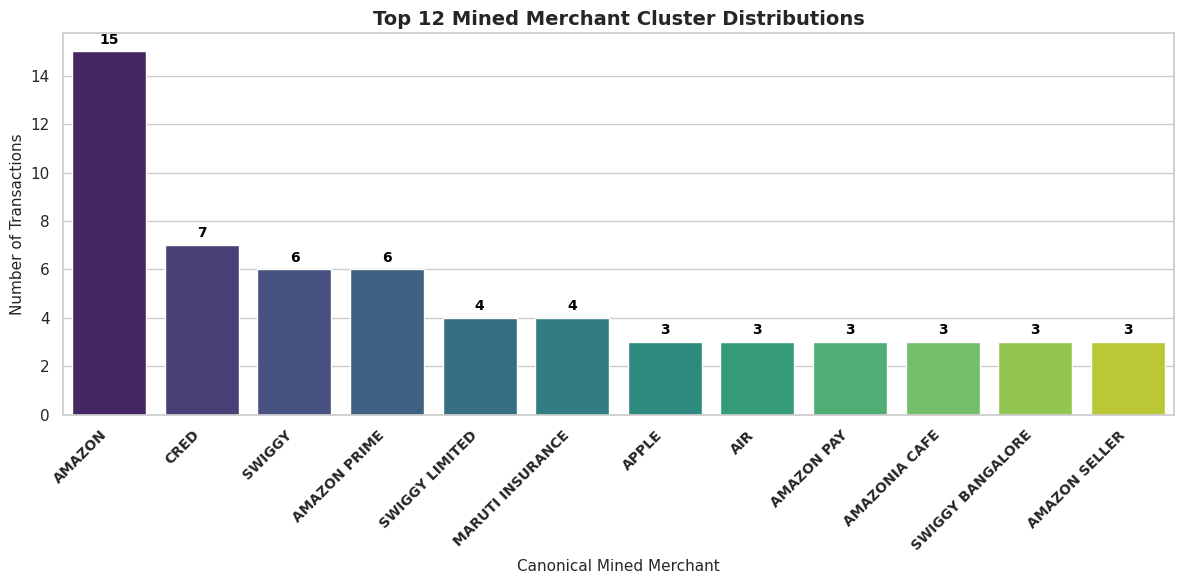

In [32]:
# =========================================================================
# CELL 8.1: CHART 1 - TOP MINED MERCHANT CLUSTER SIZES (VERTICAL)
# =========================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visualization theme
sns.set_theme(style="whitegrid", palette="muted")
plt.figure(figsize=(12, 6))

# Extract top 12 mined merchants
top_merchants = final_df['mined_merchant'].value_counts().head(12)

# Plot vertical bar chart (y=values, x=index)
ax1 = sns.barplot(x=top_merchants.index, y=top_merchants.values, palette="viridis")
plt.title("Top 12 Mined Merchant Cluster Distributions", fontsize=14, fontweight='bold')
plt.xlabel("Canonical Mined Merchant", fontsize=11)
plt.ylabel("Number of Transactions", fontsize=11)

# Rotate x-axis text labels so long merchant names stay clean and readable
plt.xticks(rotation=45, ha='right', fontsize=10, fontweight='bold')

# Annotate counts on top of each bar
for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(
        f"{int(height)}",
        (p.get_x() + p.get_width() / 2., height + 0.2),
        ha='center', va='bottom', fontsize=10, color='black', fontweight='bold'
    )

plt.tight_layout()
plt.show()